<a href="https://colab.research.google.com/github/FikarBahrul/PCVK_Ganjil_2026/blob/main/Week09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
NAMA = 'Fikar Bahrul Santoso'
NIM = '244107020160'
KELAS = 'TI-3E/08'
print('NAMA :', NAMA)
print('NIM  :', NIM)
print('KELAS:', KELAS)

NAMA : Fikar Bahrul Santoso
NIM  : 244107020160
KELAS: TI-3E/08


# **D. Tugas Praktikum**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2
import numpy as np
import math
import pandas as pd
from matplotlib import pyplot as plt
from google.colab.patches import cv2_imshow
from skimage import filters
from skimage.morphology import skeletonize
from skimage import io, color, morphology, img_as_float

# Folder citra praktikum minggu 9
base = '/content/drive/MyDrive/Semester 5/PCVK/Week09/Images/'

**Percobaan 1 - Dilasi Tanpa Library (SE Cross 3x3)**

In [ ]:
# Percobaan 1 - Dilasi tanpa library (SE berbentuk Cross 3x3)

def dilasi_citra(F, SE):
    p, q = F.shape
    kh, kw = SE.shape
    ch, cw = kh // 2, kw // 2
    imgD = np.zeros((p, q), dtype=np.uint8)

    for i in range(ch, p - ch):
        for j in range(cw, q - cw):
            temp = F[i-ch:i+ch+1, j-cw:j+cw+1]
            imgD[i, j] = np.max(temp * SE)

    return imgD

img_d = cv2.imread(base + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)

SED = np.array([[0, 1, 0],
                [1, 1, 1],
                [0, 1, 0]], dtype=np.uint8)
imgD = dilasi_citra(thresh, SED)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 2 - Dilasi dengan Library OpenCV (SE Cross 3x3)**

In [ ]:
# Percobaan 2 - Dilasi dengan library morphology OpenCV (SE Cross 3x3)

img = cv2.imread(base + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
dilasi = cv2.dilate(thresh, kernel, iterations=1)
print(kernel)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(dilasi, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 3 - Erosi Tanpa Library (SE Square 5x5)**

In [ ]:
# Percobaan 3 - Erosi tanpa library (SE berbentuk Square 5x5)

def erosi_citra(F, SE):
    m, n = F.shape
    kh, kw = SE.shape
    ch, cw = kh // 2, kw // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(ch, m - ch):
        for j in range(cw, n - cw):
            temp = F[i-ch:i+ch+1, j-cw:j+cw+1]
            imgE[i, j] = np.min(temp * SE)

    return imgE

img_e = cv2.imread(base + 'plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 255, cv2.THRESH_BINARY)

SE = np.ones((5, 5), dtype=np.uint8)
imgE = erosi_citra(thresh1, SE)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh1, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 4 - Erosi dengan Library OpenCV (SE Square 5x5)**

In [ ]:
# Percobaan 4 - Erosi dengan library morphology OpenCV (SE Square 5x5)

img = cv2.imread(base + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

kernel = np.ones((5, 5), dtype=np.uint8)
erosion = cv2.erode(thresh, kernel, iterations=1)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(erosion, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 5 - Operasi Opening Tanpa & Dengan Library (SE Square 3x3)**

In [ ]:
# Percobaan 5 - Operasi Opening (SE Square 3x3)
# Opening = erosi lalu dilasi dengan structuring element yang sama

# (a) Tanpa library
img_o = cv2.imread(base + 'plat nomer.jpg', 0)
reto, thresho = cv2.threshold(img_o, 127, 255, cv2.THRESH_BINARY)
SE_square3 = np.ones((3, 3), dtype=np.uint8)
imgO = dilasi_citra(erosi_citra(thresho, SE_square3), SE_square3)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresho, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(imgO, cmap='gray')
plt.title('Opening (Manual)'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

# (b) Dengan library morphology OpenCV
img = cv2.imread(base + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), dtype=np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Opening (Library)'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 6 - Operasi Closing Tanpa & Dengan Library (SE Square 3x3)**

In [ ]:
# Percobaan 6 - Operasi Closing (SE Square 3x3)
# Closing = dilasi lalu erosi dengan structuring element yang sama

# (a) Tanpa library
img_c = cv2.imread(base + 'plat nomer.jpg', 0)
retc, threshc = cv2.threshold(img_c, 127, 255, cv2.THRESH_BINARY)
SE_square3 = np.ones((3, 3), dtype=np.uint8)
imgC = erosi_citra(dilasi_citra(threshc, SE_square3), SE_square3)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(threshc, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(imgC, cmap='gray')
plt.title('Closing (Manual)'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

# (b) Dengan library morphology OpenCV
img = cv2.imread(base + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), dtype=np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Closing (Library)'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 7 - Dilasi dengan SE Cross 3x3 dan 5x5**

In [ ]:
# Percobaan 7 - Dilasi dengan SE Cross 3x3 dan 5x5 (tanpa library)

img_d = cv2.imread(base + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)

SED_cross3 = np.array([[0, 1, 0],
                       [1, 1, 1],
                       [0, 1, 0]], dtype=np.uint8)
SED_cross5 = np.array([[0, 0, 1, 0, 0],
                       [0, 0, 1, 0, 0],
                       [1, 1, 1, 1, 1],
                       [0, 0, 1, 0, 0],
                       [0, 0, 1, 0, 0]], dtype=np.uint8)

hasil3 = dilasi_citra(thresh, SED_cross3)
hasil5 = dilasi_citra(thresh, SED_cross5)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(hasil3, cmap='gray')
plt.title('Dilasi Cross 3x3'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(hasil5, cmap='gray')
plt.title('Dilasi Cross 5x5'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 8 - Dilasi dengan SE Circular 3x3 dan 5x5**

In [ ]:
# Percobaan 8 - Dilasi dengan SE Circular (Ellipse) 3x3 dan 5x5 (tanpa library)

img_d = cv2.imread(base + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)

SED_circle3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
SED_circle5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

hasil3 = dilasi_citra(thresh, SED_circle3)
hasil5 = dilasi_citra(thresh, SED_circle5)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(hasil3, cmap='gray')
plt.title('Dilasi Circular 3x3'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(hasil5, cmap='gray')
plt.title('Dilasi Circular 5x5'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 9 - Erosi dengan SE Rectangle 3x5 dan 5x7**

In [ ]:
# Percobaan 9 - Erosi dengan SE Rectangle 3x5 dan 5x7 (tanpa library)

img_e = cv2.imread(base + 'plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 255, cv2.THRESH_BINARY)

SE_rect_3x5 = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 3))
SE_rect_5x7 = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 5))

hasil3x5 = erosi_citra(thresh1, SE_rect_3x5)
hasil5x7 = erosi_citra(thresh1, SE_rect_5x7)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(hasil3x5, cmap='gray')
plt.title('Erosi Rectangle 3x5'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(hasil5x7, cmap='gray')
plt.title('Erosi Rectangle 5x7'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 10 - Erosi dengan SE Line Vertikal 3 dan 5**

In [ ]:
# Percobaan 10 - Erosi dengan SE Line Vertikal 3 dan 5 (tanpa library)

img_e = cv2.imread(base + 'plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 255, cv2.THRESH_BINARY)

SE_line3 = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 3))
SE_line5 = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 5))

hasil3 = erosi_citra(thresh1, SE_line3)
hasil5 = erosi_citra(thresh1, SE_line5)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(hasil3, cmap='gray')
plt.title('Erosi Line Vertikal 3'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(hasil5, cmap='gray')
plt.title('Erosi Line Vertikal 5'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 11 - Transformasi Top-Hat (White Hat)**

In [ ]:
# Percobaan 11 - Transformasi Top-Hat (White Hat)
# Top-Hat = citra asli - hasil opening citra

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

img = cv2.imread(base + 'plat nomer.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil Top-Hat'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 12 - Transformasi Black-Hat (Bottom Hat)**

In [ ]:
# Percobaan 12 - Transformasi Black-Hat (Bottom Hat)
# Black-Hat = hasil closing citra - citra asli

img = cv2.imread(base + 'kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black-Hat'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 13 - Skeleton (Rangka Objek)**

In [ ]:
# Percobaan 13 - Skeleton (Rangka Objek)

img = cv2.imread(base + 'lily.jpg', 0)

binary = img > filters.threshold_triangle(img)

# ubah nilai True/False menjadi 1/0
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

skeleton = skeletonize(binary_cp)

plt.figure(figsize=(16, 7))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Citra Asli'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('Citra Skeleton'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 14 - Skeleton Inverse**

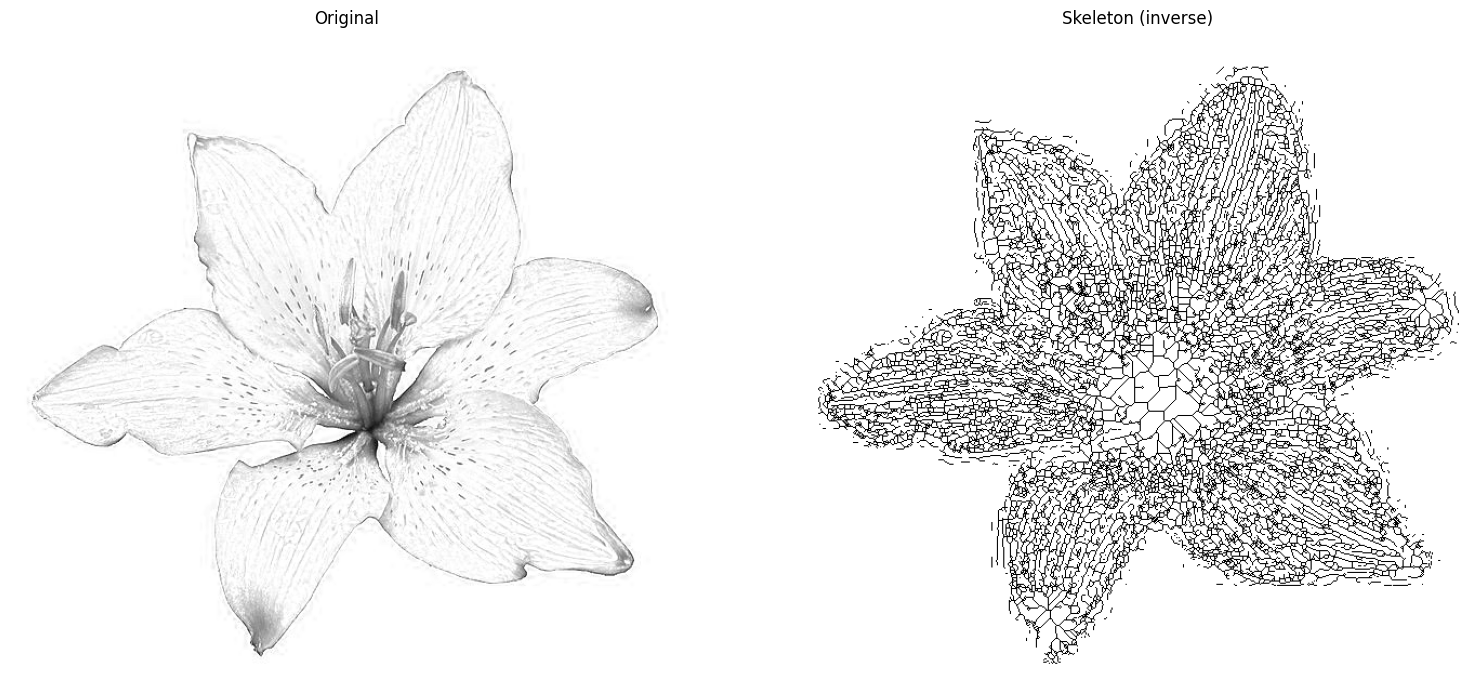

In [ ]:
# Percobaan 14 - Skeleton Inverse

img = io.imread(base + 'lily.jpg')[..., 0]

# bagian gelap dijadikan True, sehingga memakai operator <
binary = img < filters.threshold_triangle(img)

skeleton = skeletonize(binary)

fig, ax = plt.subplots(1, 2, figsize=(16, 7))

ax[0].imshow(img, cmap='gray')
ax[0].set_title('Original')
ax[0].set_axis_off()

# colormap dibalik (gray_r) agar skeleton terlihat
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('Skeleton (inverse)')
ax[1].set_axis_off()

plt.tight_layout()
plt.show()

**Percobaan 15 - Thickening / Thinning**

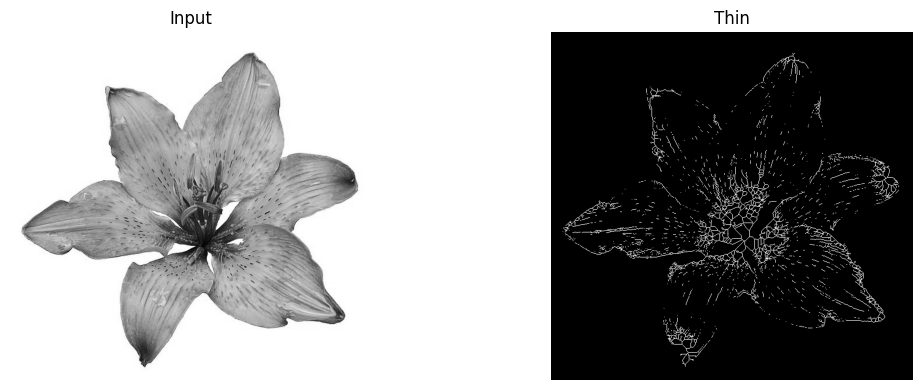

In [ ]:
# Percobaan 15 - Thickening / Thinning

image = img_as_float(color.rgb2gray(io.imread(base + 'lily.jpg')))
image_binary = image < 0.5

out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax0.set_axis_off()

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
ax1.set_axis_off()

plt.tight_layout()
plt.show()

# **D2. Tugas Praktikum - Penerapan Morfologi pada Citra KTP**

Menggunakan dataset KTP dari **Modul 7** (`ktp_fulan.jpg`, `ktp_fulani.jpg`, `ktp_fulano.jpg`). Tujuannya menerapkan operasi morfologi setelah threshold agar teks KTP lebih bersih sehingga mudah dibaca OCR.

Alur yang dipakai mengikuti studi kasus pada slide minggu 9:
1. Konversi ke **grayscale**
2. **Threshold Otsu + BINARY_INV** sebagai pembanding segmentasi (teks gelap dijadikan putih)
3. **Opening** pada citra grayscale untuk menghapus bintik/pantulan terang berukuran kecil
4. Bandingkan hasil OCR: grayscale mentah vs threshold vs hasil morfologi
5. Jelaskan mengapa pemilihan operasi dan ukuran SE berpengaruh

**1. Citra Perbandingan**

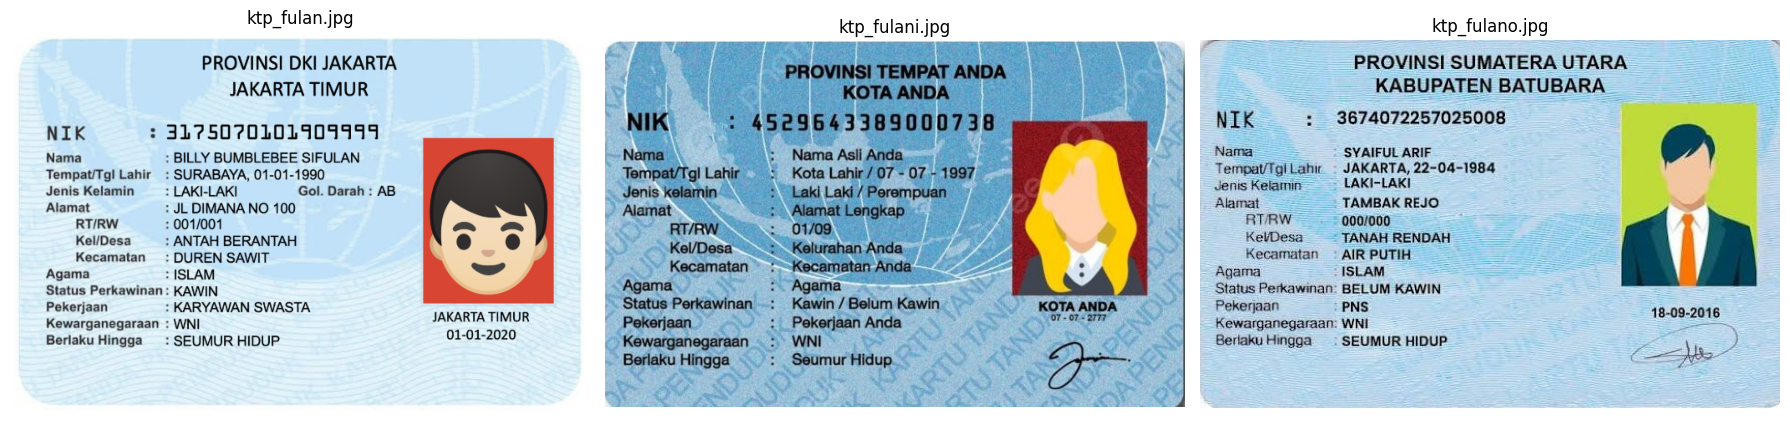

In [ ]:
ktps = ['ktp_fulan.jpg', 'ktp_fulani.jpg', 'ktp_fulano.jpg']
ktp_base = '/content/drive/MyDrive/Semester 5/PCVK/Week07/Images/'

# 1. Menampilkan ketiga citra KTP secara berdampingan

plt.figure(figsize=(18, 5))
for i, nama in enumerate(ktps):
    img = cv2.imread(ktp_base + nama)
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(nama)
    plt.axis('off')
plt.tight_layout()
plt.show()

**2. Tahapan Morfologi pada Citra KTP**

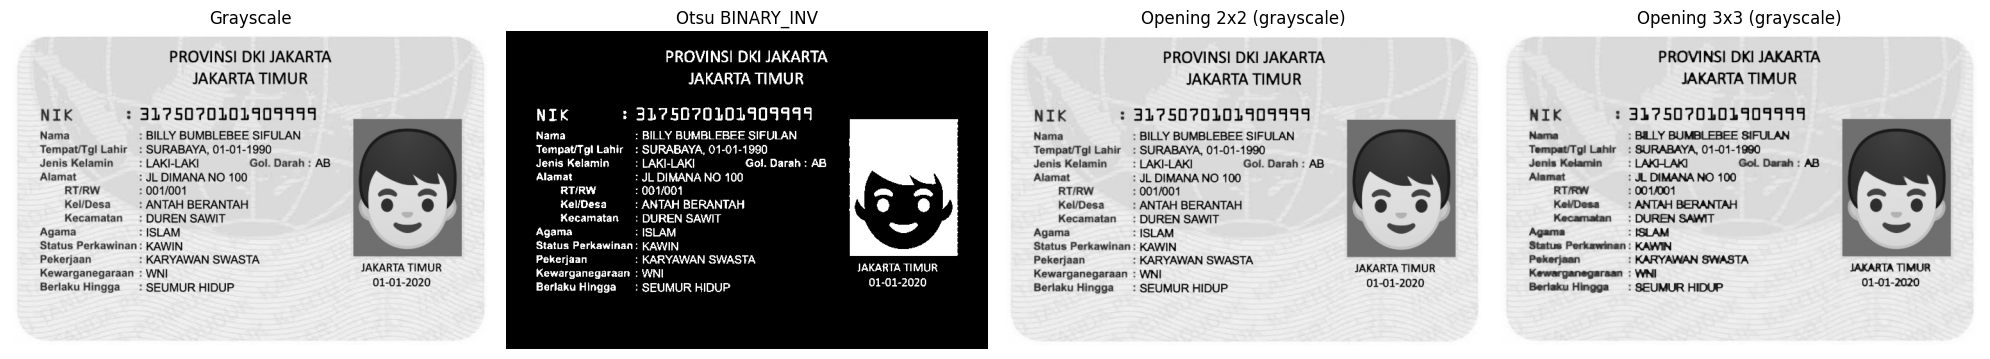

In [ ]:
# 2. Menampilkan tahapan morfologi pada salah satu KTP

def tahap_morfologi(gray):
    _, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    k_open2 = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    k_open3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    buka2 = cv2.morphologyEx(gray, cv2.MORPH_OPEN, k_open2)
    buka3 = cv2.morphologyEx(gray, cv2.MORPH_OPEN, k_open3)
    return bw, buka2, buka3

nama = 'ktp_fulan.jpg'
img = cv2.imread(ktp_base + nama)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
bw, buka2, buka3 = tahap_morfologi(gray)

plt.figure(figsize=(20, 5))
plt.subplot(141), plt.imshow(gray, cmap='gray')
plt.title('Grayscale'), plt.axis('off')
plt.subplot(142), plt.imshow(bw, cmap='gray')
plt.title('Otsu BINARY_INV'), plt.axis('off')
plt.subplot(143), plt.imshow(buka2, cmap='gray')
plt.title('Opening 2x2 (grayscale)'), plt.axis('off')
plt.subplot(144), plt.imshow(buka3, cmap='gray')
plt.title('Opening 3x3 (grayscale)'), plt.axis('off')
plt.tight_layout()
plt.show()

**3. Perbandingan Hasil OCR Sebelum dan Sesudah Morfologi**

In [ ]:
# 3. OCR pada citra asli, hasil threshold, dan hasil morfologi
!sudo apt-get install -y tesseract-ocr > /dev/null 2>&1
!pip install pytesseract > /dev/null 2>&1

import pytesseract

# 10 kata/angka yang terlihat jelas sebagai acuan (gabungan ketiga citra KTP, Modul 7)
acuan = [
    ('ktp_fulan.jpg', '3175070101909999'),
    ('ktp_fulan.jpg', 'BILLY BUMBLEBEE SIFULAN'),
    ('ktp_fulan.jpg', 'SURABAYA'),
    ('ktp_fulan.jpg', '01-01-1990'),
    ('ktp_fulano.jpg', '3674072255025008'),
    ('ktp_fulano.jpg', 'SYAIFUL ARIF'),
    ('ktp_fulano.jpg', 'JAKARTA'),
    ('ktp_fulano.jpg', '22-04-1984'),
    ('ktp_fulani.jpg', '4529643389000738'),
    ('ktp_fulani.jpg', '07 - 07 - 1997'),
]

metode_list = ['Grayscale asli', 'Otsu BINARY_INV', 'Grayscale + Opening 2x2']

def masukan_ocr(img_bgr, metode):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    if metode == 'Grayscale asli':
        return gray
    if metode == 'Otsu BINARY_INV':
        _, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        return bw
    # morfologi: opening pada grayscale menghapus bintik terang kecil tanpa merusak huruf
    k_open = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    return cv2.morphologyEx(gray, cv2.MORPH_OPEN, k_open)

def ocr_teks(gambar):
    return pytesseract.image_to_string(gambar)

# Normalisasi: abaikan huruf besar/kecil serta spasi berlebih di awal/akhir
def normal(teks):
    return ' '.join(teks.lower().split())

ocr_mentah = {}
for m in metode_list:
    for nama in ktps:
        img_bgr = cv2.imread(ktp_base + nama)
        ocr_mentah[(m, nama)] = normal(ocr_teks(masukan_ocr(img_bgr, m)))

hasil = {m: [] for m in metode_list}
for nama, teks in acuan:
    for m in metode_list:
        hasil[m].append('Cocok' if normal(teks) in ocr_mentah[(m, nama)] else 'Tidak')

tabel = pd.DataFrame({
    'No.': range(1, len(acuan) + 1),
    'Teks sebenarnya': [t for _, t in acuan],
    'Grayscale asli': hasil['Grayscale asli'],
    'Otsu BINARY_INV': hasil['Otsu BINARY_INV'],
    'Grayscale + Opening 2x2': hasil['Grayscale + Opening 2x2'],
})
print(tabel.to_string(index=False))

**Tabel perbandingan hasil pembacaan dengan tulisan sebenarnya** (isi sesuai hasil OCR).

| No. | Teks sebenarnya | Grayscale asli | Otsu BINARY_INV | Grayscale + Opening 2x2 |
|-----|-----------------|----------------|-----------------|------------------|
| 1 | 3175070101909999 | Tidak | Tidak | Cocok |
| 2 | BILLY BUMBLEBEE SIFULAN | Cocok | Cocok | Cocok |
| 3 | SURABAYA | Cocok | Cocok | Cocok |
| 4 | 01-01-1990 | Cocok | Cocok | Cocok |
| 5 | 3674072255025008 | Tidak | Tidak | Tidak |
| 6 | SYAIFUL ARIF | Tidak | Tidak | Cocok |
| 7 | JAKARTA | Cocok | Cocok | Cocok |
| 8 | 22-04-1984 | Cocok | Cocok | Cocok |
| 9 | 4529643389000738 | Cocok | Cocok | Cocok |
| 10 | 07 - 07 - 1997 | Cocok | Tidak | Cocok |

Penilaian dilakukan pada teks hasil OCR, bukan hanya pada kata yang diberi kotak.

**4. Menghitung Persentase Kecocokan untuk Setiap Metode**

In [ ]:
# 4. Menghitung persentase kecocokan untuk setiap metode

jumlah_acuan = len(acuan)

tabel_akhir = []
for m in metode_list:
    benar = hasil[m].count('Cocok')
    tabel_akhir.append({
        'Citra masukan OCR': m,
        'Item terbaca tepat': benar,
        'Kecocokan (%)': round(benar / jumlah_acuan * 100, 1),
    })

ringkasan_tabel = pd.DataFrame(tabel_akhir)
print(ringkasan_tabel.to_string(index=False))

**Tabel ringkasan**

| Citra masukan OCR | Item terbaca tepat | Kecocokan (%) |
|-------------------|--------------------|---------------|
| Grayscale asli | 7 | 70.0 |
| Otsu BINARY_INV | 6 | 60.0 |
| Grayscale + Opening 2x2 | 9 | 90.0 |

Catatan: item dinyatakan **cocok** hanya jika seluruh huruf/angka pada item sama dengan acuan.

**Pertanyaan analisis :**

1. Apa perbedaan hasil dilasi manual (tanpa library) dengan dilasi menggunakan library OpenCV?
2. Bagaimana bentuk dan ukuran structuring element (SE) memengaruhi hasil erosi dan dilasi? Bandingkan SE cross, circular, rectangle, dan line.
3. Jelaskan perbedaan operasi opening dan closing berdasarkan hasil percobaan.
4. Apa hubungan transformasi Top-Hat dan Black-Hat dengan operasi opening dan closing?
5. Apa kelebihan representasi skeleton dibandingkan citra biner aslinya?
6. Operasi morfologi apa yang paling membantu keterbacaan teks KTP? Jelaskan alasannya.

**Jawaban:**

1. Secara visual hasil dilasi manual dan dilasi OpenCV identik, karena keduanya mengambil nilai maksimum pada jendela SE yang sama. Perbedaannya hanya pada cara implementasi: versi manual memakai perulangan piksel dengan perkalian SE, sedangkan `cv2.dilate` memakai implementasi yang sudah dioptimasi dan menganggap piksel di luar batas citra sebagai latar. Menulis versi manual membuat proses fit/hit/miss SE lebih mudah dipahami.

2. Bentuk SE menentukan arah penebalan/penipisan. SE cross menebalkan ke empat arah utama sehingga sudut tetap relatif tajam, SE circular/ellipse menyebar merata ke segala arah sehingga hasil objek cenderung membulat, SE rectangle melebar ke arah horizontal/vertikal sesuai ukurannya, dan SE line vertikal hanya mengubah ukuran ke arah vertikal. Ukuran SE juga berpengaruh: makin besar SE, makin tebal hasil dilasi atau makin tipis hasil erosi. Contohnya, dilasi cross 5x5 menebalkan objek lebih banyak daripada cross 3x3.

3. Opening (erosi lalu dilasi) menghilangkan bintik-bintik terang kecil dan memutus sambungan tipis tanpa mengubah ukuran objek utama, sehingga berguna untuk membersihkan noise luar objek. Closing (dilasi lalu erosi) justru menutup lubang kecil dan menyambung goresan pada objek tanpa mengubah ukuran objek utama. Jadi opening cenderung mengurangi bagian terang kecil, sedangkan closing menambah/menutup bagian gelap kecil.

4. Top-Hat adalah citra asli dikurangi hasil opening, sehingga menonjolkan detail terang yang lebih kecil dari SE. Black-Hat adalah hasil closing dikurangi citra asli, sehingga menonjolkan detail gelap yang lebih kecil dari SE. Keduanya hanya memanfaatkan elemen dasar: Top-Hat memakai opening, sedangkan Black-Hat memakai closing.

5. Skeleton adalah representasi objek setipis mungkin (1-2 piksel) yang tetap mempertahankan ukuran, posisi, dan topologi bentuk aslinya. Kelebihannya: ukuran data jauh lebih kecil, struktur objek lebih mudah dianalisis (misalnya panjang dan jumlah cabang), namun pola objek tetap dapat dikenali. Skeleton juga bersifat stabil karena bagian yang sudah terbentuk tidak terkikis lagi pada iterasi berikutnya.

6. Operasi yang paling membantu pada dataset ini adalah opening dengan SE kecil (2x2) yang diterapkan langsung pada citra grayscale. Opening menghapus bintik terang kecil akibat noise dan pantulan tanpa merusak bentuk utama huruf, sehingga jumlah item yang terbaca naik dari 7 menjadi 9. Sebaliknya, ketika morfologi diterapkan setelah threshold biner dengan SE lebih besar, huruf tipis ikut terhapus dan hasil OCR justru menurun. Jadi domain penerapan (grayscale vs biner) dan ukuran SE sangat menentukan.

## Ringkasan Analisis dan Kesimpulan Praktikum

**Percobaan 1-2 - Dilasi Manual dan Library**

Dilasi menebalkan objek dengan mengambil nilai maksimum di dalam jendela SE. Hasil dilasi manual dan `cv2.dilate` sama; versi manual berguna untuk memahami proses fit/hit/miss, sedangkan library lebih ringkas dan cepat.

**Percobaan 3-4 - Erosi Manual dan Library**

Erosi menipiskan objek dengan mengambil nilai minimum di dalam jendela SE. Erosi menghapus noise/objek kecil dan memisahkan objek yang bersentuhan, dan hasilnya sama antara versi manual dengan `cv2.erode`.

**Percobaan 5 - Opening**

Opening (erosi lalu dilasi) menghilangkan bintik terang kecil dan memutus sambungan 1-2 piksel tanpa mengubah ukuran objek utama secara signifikan. Operasi ini idempotent.

**Percobaan 6 - Closing**

Closing (dilasi lalu erosi) menutup lubang kecil di dalam objek dan menyambung goresan yang terputus. Seperti opening, operasi ini juga idempotent.

**Percobaan 7-8 - Variasi Dilasi (Cross dan Circular)**

Bentuk SE memengaruhi arah penebalan. SE cross menebalkan ke arah horizontal dan vertikal, sedangkan SE circular menebalkan merata sehingga hasil lebih membulat. Ukuran SE yang lebih besar memperbesar efek penebalan.

**Percobaan 9-10 - Variasi Erosi (Rectangle dan Line)**

SE rectangle dan line vertikal menghasilkan erosi yang bergantung arah. SE line vertikal menipiskan objek hanya ke arah vertikal, sedangkan rectangle sesuai rasio lebarnya. Semakin besar ukuran SE, semakin banyak piksel tepi yang terhapus.

**Percobaan 11 - Top-Hat**

Top-Hat (citra asli dikurangi opening) menonjolkan detail terang yang lebih kecil dari SE, berguna untuk objek kecil terang pada pencahayaan tidak merata.

**Percobaan 12 - Black-Hat**

Black-Hat (closing dikurangi citra asli) menonjolkan detail gelap yang lebih kecil dari SE, misalnya teks gelap pada latar terang.

**Percobaan 13-15 - Skeleton dan Thinning**

Skeleton menghasilkan rangka objek setipis 1-2 piksel yang tetap mempertahankan ukuran, posisi, dan topologi. Skeleton inverse menonjolkan rangka pada latar gelap, sedangkan thinning menipiskan objek secara iteratif sampai tidak ada perubahan.

**Tugas Praktikum - Morfologi pada Citra KTP**

Morfologi adalah tahap pembersihan yang membantu menonjolkan teks KTP. Opening dengan SE kecil (2x2) pada citra grayscale menghapus bintik terang kecil akibat noise dan pantulan sehingga teks lebih bersih dan OCR meningkat (9 dari 10 item, dibandingkan 7 pada grayscale mentah dan 6 pada threshold Otsu BINARY_INV). Pemilihan operasi dan ukuran SE sangat menentukan: SE yang terlalu besar (3x3) justru menghapus goresan huruf tipis sehingga keterbacaan menurun.

**Kesimpulan Praktikum**

Erosi dan dilasi adalah operasi dasar yang seluruh operasi morfologi lainnya dibangun darinya: opening untuk menghapus noise terang, closing untuk menutup lubang gelap, Top-Hat dan Black-Hat untuk mengekstrak detail terang/gelap berukuran kecil, serta skeleton dan thinning untuk memperoleh rangka objek. Structuring element berperan sebagai 'stempel' yang menentukan bentuk dan besar perubahan, sehingga pemilihan bentuk serta ukuran SE harus disesuaikan dengan cacat pada mask yang ingin diperbaiki.